u# S³ semantic-axis smoke test

This exploratory test fits Turftopic S³ to the existing semantic passages using the saved BGE-M3 vectors. Passage embeddings are loaded from disk and passed through `embeddings=`; they are not recomputed. The matching local BGE model is used only for vocabulary-term embeddings.

This fit uses 20 components and seed 43. Scores are signed ICA coordinates, not calibrated probabilities or BERTopic topics. Review the displayed positive/negative evidence before interpreting an axis. Original BERTopic assignments are not changed.

Run from the repository root with `uv run --group topic-analysis jupyter lab`.

In [ ]:
 eview axis 5 first

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import CountVectorizer
from turftopic import SemanticSignalSeparation

project_root = Path.cwd().resolve()
if not (project_root / 'data/topic-analysis').exists():
    project_root = project_root.parent
if not (project_root / 'data/topic-analysis').exists():
    raise FileNotFoundError('Could not locate data/topic-analysis from the notebook working directory')
results = project_root / 'data/topic-analysis/results'
dataset_path = results / 'segment-dataset/all-segments.parquet'
embedding_path = results / 'jev-semantic-all/bubble-maps/segment-embeddings.npy'
embedding_manifest_path = results / 'jev-semantic-all/bubble-maps/embedding-manifest.json'
model_manifest_path = results / 'segment-dataset/manifest.json'
MODEL_ID = 'BAAI/bge-m3'
MODEL_REVISION = '5617a9f61b028005a4858fdac845db406aefb181'
N_COMPONENTS, RANDOM_STATE = 20, 43
print(f'Project: {project_root}')
print(f'Saved vectors: {embedding_path}')

Project: C:\Users\risto\projects\arvamusfestivali_salvestused
Saved vectors: C:\Users\risto\projects\arvamusfestivali_salvestused\data\topic-analysis\results\jev-semantic-all\bubble-maps\segment-embeddings.npy


C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\_snmf.py:20: UserWarning: JAX not found, continuing with NumPy implementation.
  warnings.warn("JAX not found, continuing with NumPy implementation.")


In [2]:
wanted = ['segment_key', 'segmentation', 'passage_id', 'episode_id', 'title', 'start_seconds', 'end_seconds', 'text', 'audio_url', 'topic_id', 'membership_strength']
available = set(pd.read_parquet(dataset_path).columns)
all_passages = pd.read_parquet(dataset_path, columns=[c for c in wanted if c in available])
passages = all_passages.loc[all_passages.segmentation == 'semantic'].reset_index(drop=True)
embedding_manifest = json.loads(embedding_manifest_path.read_text(encoding='utf-8'))
model_info = json.loads(model_manifest_path.read_text(encoding='utf-8'))['models']['semantic']
embeddings = np.load(embedding_path, allow_pickle=False)
assert model_info['embedding_model_id'] == MODEL_ID
assert model_info['embedding_revision'] == MODEL_REVISION
assert int(model_info['embedding_dimension']) == 1024
assert passages.segment_key.tolist() == embedding_manifest['segment_keys'], 'Passage/vector order mismatch'
assert embeddings.shape == (len(passages), 1024), embeddings.shape
assert embeddings.dtype == np.float32 and np.isfinite(embeddings).all()
assert np.allclose(np.linalg.norm(embeddings, axis=1), 1.0, atol=1e-4), 'Vectors are not L2-normalized'
print(f'Validated {len(passages):,} passages × {embeddings.shape[1]} dimensions; float32, finite, L2-normalized.')
print(f"Model: {model_info['embedding_model_id']} @ {model_info['embedding_revision']}")
print(f"Original BERTopic outliers (topic -1): {(passages.topic_id == -1).sum():,}")

Validated 4,132 passages × 1024 dimensions; float32, finite, L2-normalized.
Model: BAAI/bge-m3 @ 5617a9f61b028005a4858fdac845db406aefb181
Original BERTopic outliers (topic -1): 827


## Fit on the precomputed vectors

The encoder is loaded from local cache only. If that exact revision is not cached, the cell fails instead of downloading or substituting another model. Turftopic receives the corpus matrix directly via `embeddings=embeddings`.

In [3]:
encoder = SentenceTransformer(MODEL_ID, revision=MODEL_REVISION, local_files_only=True)
s3 = SemanticSignalSeparation(n_components=N_COMPONENTS, encoder=encoder, vectorizer=CountVectorizer(max_features=500), random_state=RANDOM_STATE)
scores = s3.fit_transform(passages.text.tolist(), embeddings=embeddings)
assert scores.shape == (len(passages), N_COMPONENTS), scores.shape
assert np.isfinite(scores).all(), 'S³ scores contain non-finite values'
score_columns = [f's3_component_{i}' for i in range(N_COMPONENTS)]
scored_passages = passages.copy()
for i, column in enumerate(score_columns):
    scored_passages[column] = scores[:, i]
print(f'S³ fit passed: {len(passages):,} passages, {N_COMPONENTS} components, seed {RANDOM_STATE}.')
print('Passage vectors came from disk; no passage re-embedding was run.')

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Output()

C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\sklearn\decompositio
n\_fastica.py:132: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum 
number of iterations.
  warnings.warn(

[18:01:01] Decomposition done.                                                                        ]8;id=88367;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py\decomp.py]8;;\:]8;id=690237;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py#156\156]8;;\

[18:01:03] Term extraction done.                                                                      ]8;id=210385;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py\decomp.py]8;;\:]8;id=707920;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py#159\159]8;;\

[18:01:08] Vocabulary encoded.                                                                        ]8;id=88660;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py\decomp.py]8;;\:]8;id=36449;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py#169\169]8;;\

           Model fitting done.                                                                        ]8;id=634505;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py\decomp.py]8;;\:]8;id=863506;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py#189\189]8;;\

S³ fit passed: 4,132 passages, 20 components, seed 43.
Passage vectors came from disk; no passage re-embedding was run.


## S³ component summary and naming evidence

S³ returns continuous bipolar axes, not discrete topic assignments. The dominant-axis count below is only an exploratory tally: each passage is counted under the component with its largest absolute standardized score. It is not a cluster count or a calibrated classification. For naming, review Turftopic's high/low term lists alongside the positive/negative extreme passages below, then enter a human-reviewed bipolar label; no labels are generated automatically.

In [4]:
score_frame = pd.DataFrame(scores, columns=score_columns)
score_std = score_frame.std(ddof=0).replace(0, 1)
score_z = (score_frame - score_frame.mean()) / score_std
dominant_component_index = np.abs(score_z.to_numpy()).argmax(axis=1)
dominant_counts = pd.Series(dominant_component_index).value_counts().reindex(range(N_COMPONENTS), fill_value=0)
positive_terms = s3.get_top_words(top_k=12, positive=True)
negative_terms = s3.get_top_words(top_k=12, positive=False)

component_stats = pd.DataFrame({
    'component_id': range(N_COMPONENTS),
    'passage_count': len(score_frame),
    'score_nan_count': score_frame.isna().sum().to_numpy(),
    'positive_score_count': score_frame.gt(0).sum().to_numpy(),
    'negative_score_count': score_frame.lt(0).sum().to_numpy(),
    'mean_score': score_frame.mean().to_numpy(),
    'score_std': score_frame.std(ddof=0).to_numpy(),
    'min_score': score_frame.min().to_numpy(),
    'max_score': score_frame.max().to_numpy(),
    'dominant_axis_passages_exploratory': dominant_counts.to_numpy(),
})
print(f'S³ passages scored: {len(score_frame):,}; missing passage texts: {passages.text.isna().sum():,}; blank passage texts: {(passages.text.notna() & passages.text.astype("string").str.strip().eq("")).sum():,}')
print('Continuous score distribution and exploratory dominant-axis counts (not topic membership)')
display(component_stats)

axis_review = pd.DataFrame({
    'component_id': range(N_COMPONENTS),
    'positive_end_terms': [', '.join(words) for words in positive_terms],
    'negative_end_terms': [', '.join(words) for words in negative_terms],
    'reviewed_bipolar_label': ['' for _ in range(N_COMPONENTS)],
    'review_notes': ['' for _ in range(N_COMPONENTS)],
})
print('Naming evidence: use both ends of each axis and verify them against the extreme passages in the next cell.')
display(axis_review)
assert int(component_stats.passage_count.iloc[0]) == len(passages)
assert int(component_stats.score_nan_count.sum()) == int(score_frame.isna().sum().sum())
assert int(component_stats.dominant_axis_passages_exploratory.sum()) == len(passages)
print(f"S3_COMPONENT_STATS_OK passages={len(passages):,}; components={N_COMPONENTS}; missing_scores={int(score_frame.isna().sum().sum())}")

S³ passages scored: 4,132; missing passage texts: 0; blank passage texts: 0
Continuous score distribution and exploratory dominant-axis counts (not topic membership)


,component_id,passage_count,score_nan_count,positive_score_count,negative_score_count,mean_score,score_std,min_score,max_score,dominant_axis_passages_exploratory
0,0,4132,0,1940,2192,-3.397407e-07,1.0,-3.053564,5.639717,188
1,1,4132,0,2439,1693,5.539250e-08,1.0,-4.596707,2.294944,229
2,2,4132,0,1688,2444,1.338652e-07,1.0,-2.238208,4.813993,201
3,3,4132,0,2373,1759,3.692834e-07,1.0,-5.330178,2.391451,221
4,4,4132,0,2102,2030,-2.021826e-07,1.0,-3.192430,2.592832,123
5,5,4132,0,1467,2665,-4.099045e-07,1.0,-1.903836,4.003488,291
6,6,4132,0,2096,2036,-2.289557e-07,1.0,-3.387366,2.951811,196
7,7,4132,0,2011,2121,3.138909e-08,1.0,-3.879850,4.255782,199
8,8,4132,0,2066,2066,-3.988260e-07,1.0,-4.298745,3.492599,187
9,9,4132,0,1680,2452,-2.732697e-07,1.0,-2.151226,4.050641,243


Naming evidence: use both ends of each axis and verify them against the extreme passages in the next cell.


,component_id,positive_end_terms,negative_end_terms,reviewed_bipolar_label,review_notes
0,0,"riigi, vastu, tööle, riik, teen, jääb, saa, en...","selle, selge, mitu, selles, sellele, selgelt, ...",,
1,1,"kooli, mulle, sul, koolis, mõju, eks, suur, ol...","ai, it, id, asi, alati, aeg, kasutada, aitäh, ...",,
2,2,"kelle, kes, oleme, olen, teeme, tean, olin, ke...","no, põhimõtteliselt, võimalik, ikkagi, öelda, ...",,
3,3,"tahaks, arvan, kindlasti, edasi, parem, tuleva...","töö, tööd, tööle, probleem, puhul, jooksul, jä...",,
4,4,"noor, head, noh, raha, mõte, eriti, arust, min...","ütlesid, ütleks, olid, peavad, võiks, olnud, j...",,
5,5,"hea, ees, selles, hoida, raske, palun, puhul, ...","kolm, vot, pool, midagi, kolmkümmend, asjad, k...",,
6,6,"riigi, riik, tööle, lapsed, protsenti, eesti, ...","mõtlema, ennast, noh, mõttes, inimese, mind, n...",,
7,7,"läks, tore, läinud, kiiresti, in, väike, kinni...","küsida, arutelu, kõigile, räägime, öelda, rääk...",,
8,8,"lahti, kellel, kooli, juures, palun, vastu, ki...","kakskümmend, aastat, protsenti, kolmkümmend, k...",,
9,9,"koolis, õpetaja, kooli, kord, teen, tead, eesm...","inimesi, inimesed, inimeste, inimest, inimene,...",,


S3_COMPONENT_STATS_OK passages=4,132; components=20; missing_scores=0


## 2-D view of the S³ axes

Each panel shows the same passage map: a PCA projection of the already-saved embeddings. Color shows the signed standardized S³ score for that panel's axis; outlined points are original BERTopic outliers (`topic_id == -1`). The map is only a 2-D projection and does not define clusters or topics.

The table below gives one strongest positive and negative evidence passage per axis, alongside top terms. These are evidence for human review, not automatic topic names.

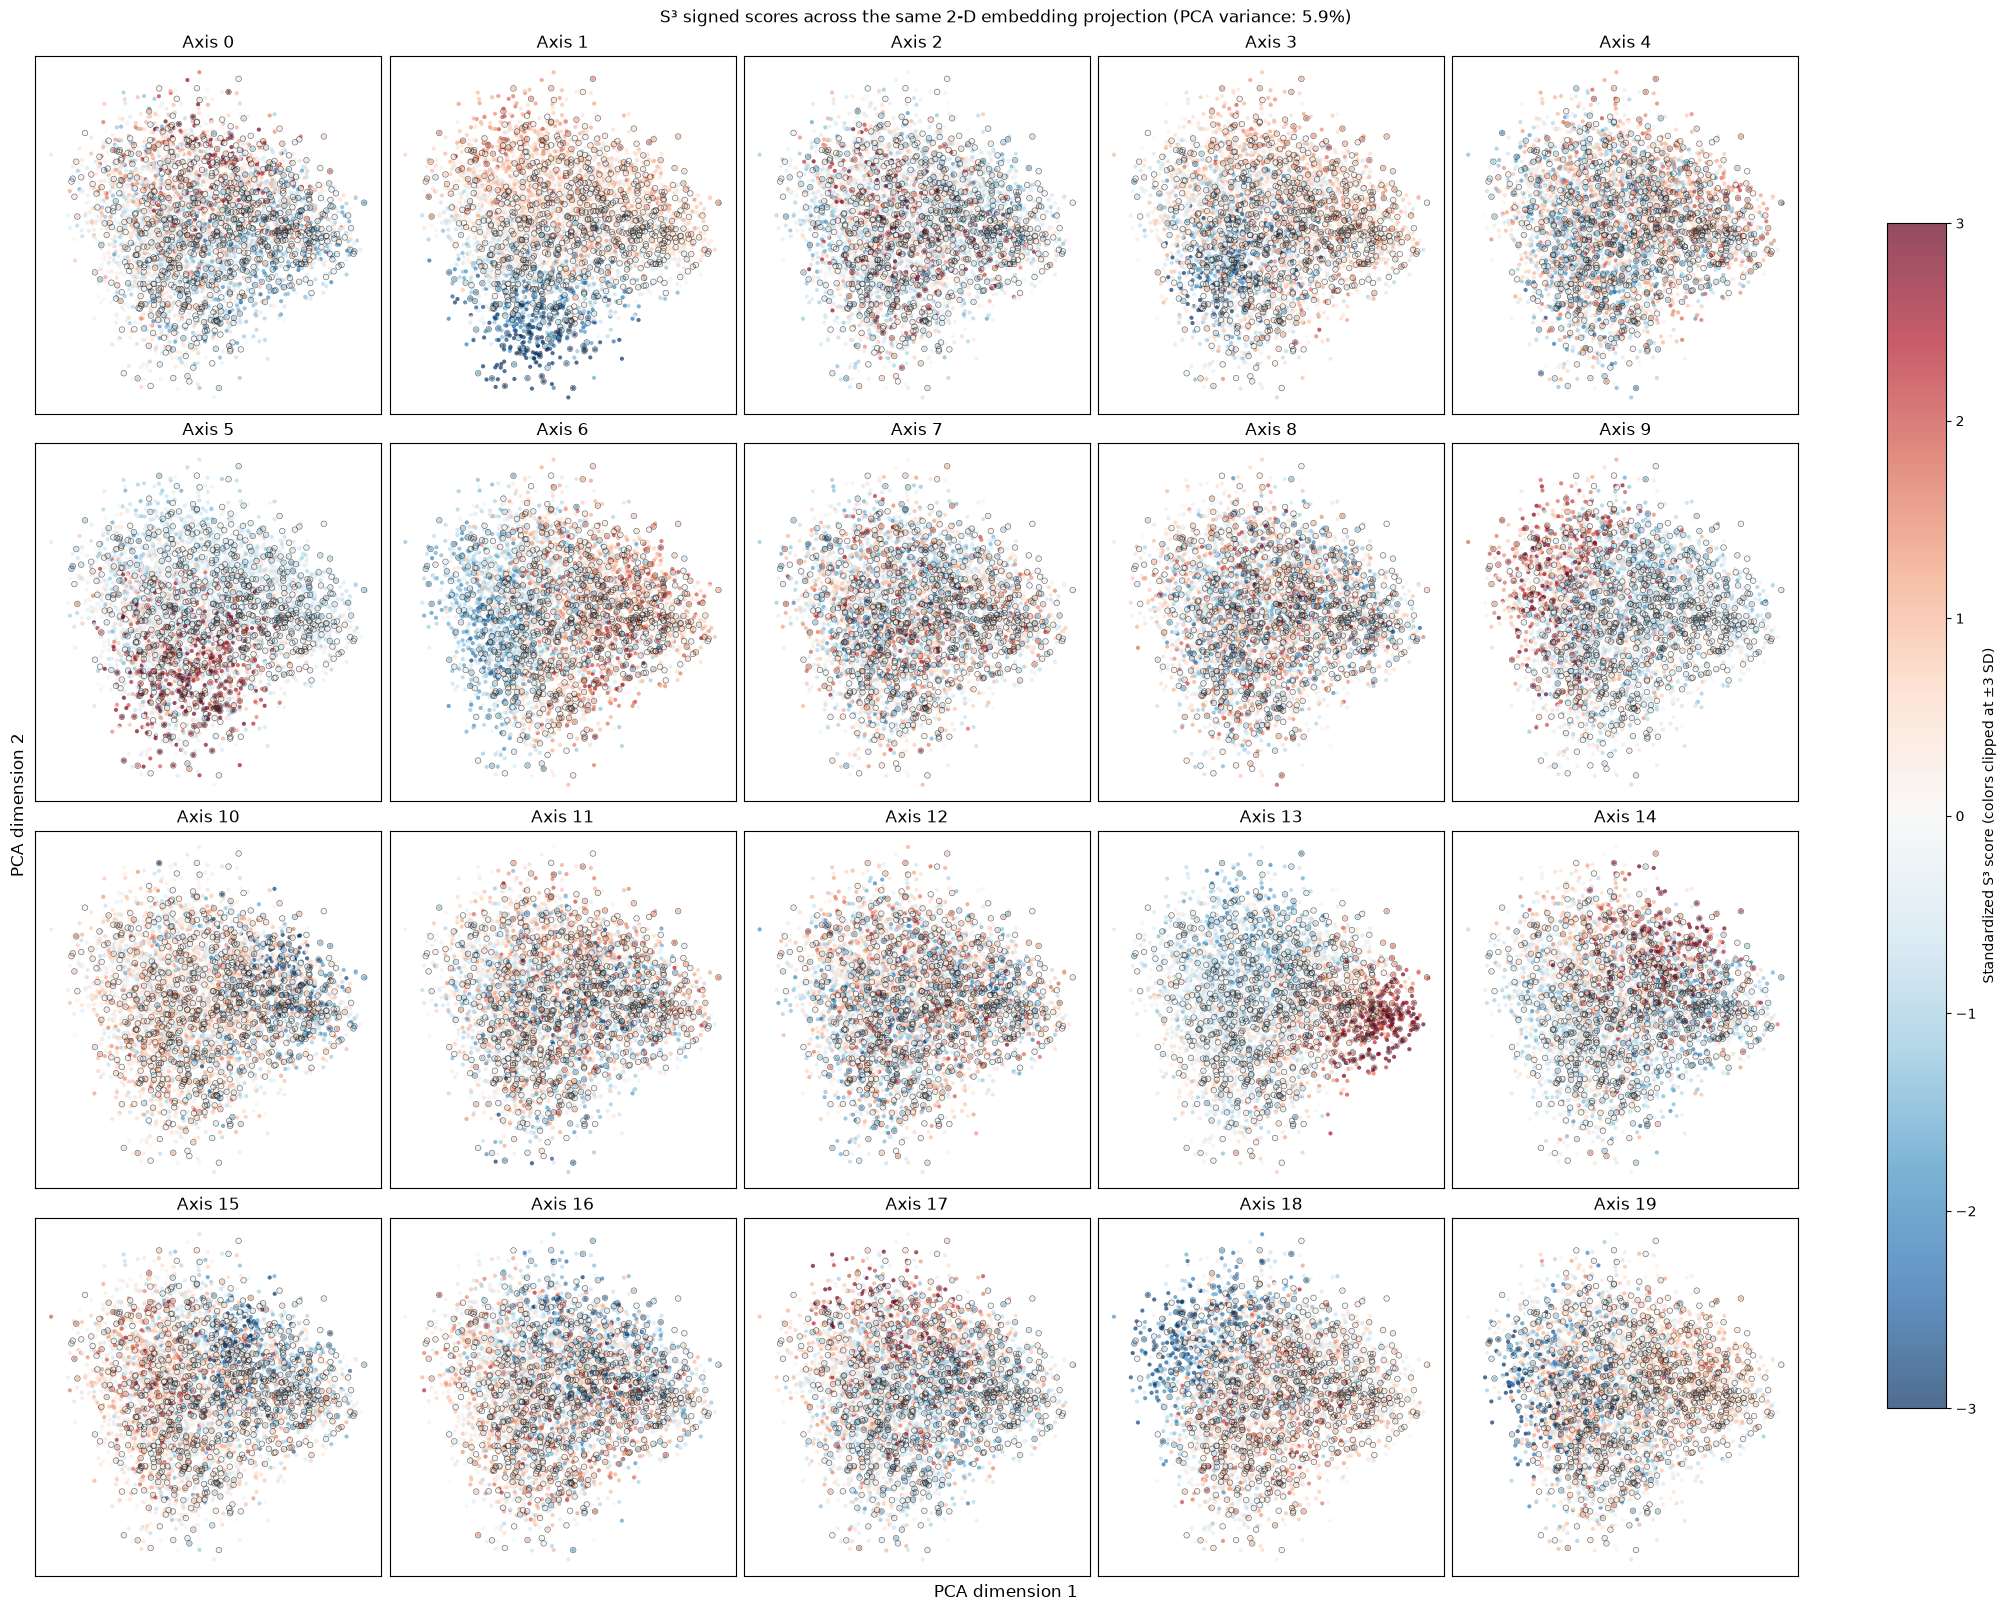

2-D projection uses the saved 1024-D vectors for 4,132 passages; BERTopic outliers outlined: 827.
Strongest passage at each end of each component; use both poles and review the linked transcript/audio before naming an axis.


,axis,positive terms,positive passage,negative terms,negative passage
0,0,"riigi, vastu, tööle, riik, teen, jääb, saa, en...",2271676352 | Ajalugu oleviku teejuhina – krist...,"selle, selge, mitu, selles, sellele, selgelt, ...",2397177252 | Tehisintellekt kultuuris – kas lo...
1,1,"kooli, mulle, sul, koolis, mõju, eks, suur, ol...","2396670933 | Kui pole mugav, siis ei kaasa_! |...","ai, it, id, asi, alati, aeg, kasutada, aitäh","2400184983 | Post-it, pastakas ja AI-agent - E..."
2,2,"kelle, kes, oleme, olen, teeme, tean, olin, ke...","2254333406 | Kuhu pöörad, rohepööre_ | 110.92–...","no, põhimõtteliselt, võimalik, ikkagi, öelda, ...",2397264588 | Mille taha jääb majanduskasv_ | 1...
3,3,"tahaks, arvan, kindlasti, edasi, parem, tuleva...",2310594926 | Mis on Eesti hariduse eesmärk.alp...,"töö, tööd, tööle, probleem, puhul, jooksul, jä...",2247188693 | Töökius otse laval | 854.4–1248.7...
4,4,"noor, head, noh, raha, mõte, eriti, arust, mind",2247188702 | Kuidas juhtida riiki? Visiooni põ...,"ütlesid, ütleks, olid, peavad, võiks, olnud, j...",2396692752 | Tuleviku Eesti edulugu_ majandusk...
5,5,"hea, ees, selles, hoida, raske, palun, puhul, ...",2400207750 | Eesti terviseandmed_ kristallkuul...,"kolm, vot, pool, midagi, kolmkümmend, asjad, k...",2277338243 | Maailmahariduslik mälumäng ja mõt...
6,6,"riigi, riik, tööle, lapsed, protsenti, eesti, ...",2400207741 | Kuidas rahastada terviseidusid ni...,"mõtlema, ennast, noh, mõttes, inimese, mind, n...",2383011942 | Kuidas hoida tervet mõistust krii...
7,7,"läks, tore, läinud, kiiresti, in, väike, kinni...",2247188684 | Kas kiirustades elad kauem? | 435...,"küsida, arutelu, kõigile, räägime, öelda, rääk...",2383011948 | Nõusolek – seksikuse summutaja võ...
8,8,"lahti, kellel, kooli, juures, palun, vastu, ki...",2397177258 | Kas tänavakunst peaks olema legaa...,"kakskümmend, aastat, protsenti, kolmkümmend, k...",2400207750 | Eesti terviseandmed_ kristallkuul...
9,9,"koolis, õpetaja, kooli, kord, teen, tead, eesm...",2289585032 | Tehisaru koolipingis. Kas õpetaja...,"inimesi, inimesed, inimeste, inimest, inimene,...",2250797873 | Vasakpoolsus Eestis. Kas turumõtl...


In [5]:
projection = PCA(n_components=2, svd_solver='randomized', random_state=RANDOM_STATE).fit_transform(embeddings)
assert projection.shape == (len(passages), 2) and np.isfinite(projection).all()
projection_variance = PCA(n_components=2, svd_solver='randomized', random_state=RANDOM_STATE).fit(embeddings).explained_variance_ratio_.sum()
outlier_mask = passages.topic_id.eq(-1).to_numpy()
ncols = min(5, N_COMPONENTS)
nrows = (N_COMPONENTS + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4 * nrows), sharex=True, sharey=True, constrained_layout=True)
axes = np.asarray(axes).reshape(-1)
for component_id, ax in enumerate(axes):
    if component_id >= N_COMPONENTS:
        ax.set_visible(False)
        continue
    values = score_z.iloc[:, component_id].to_numpy()
    ax.scatter(projection[:, 0], projection[:, 1], c=values, cmap='RdBu_r', vmin=-3, vmax=3, s=9, alpha=0.7, linewidths=0, rasterized=True)
    ax.scatter(projection[outlier_mask, 0], projection[outlier_mask, 1], facecolors='none', edgecolors='#222222', s=16, linewidths=0.45, alpha=0.7, rasterized=True)
    ax.set_title(f'Axis {component_id}')
    ax.set_xticks([]); ax.set_yticks([])
fig.supxlabel('PCA dimension 1'); fig.supylabel('PCA dimension 2')
fig.suptitle(f'S³ signed scores across the same 2-D embedding projection (PCA variance: {projection_variance:.1%})')
fig.colorbar(axes.flat[0].collections[0], ax=axes.ravel().tolist(), label='Standardized S³ score (colors clipped at ±3 SD)', shrink=0.78)
plt.show()

assert len(score_z.columns) == N_COMPONENTS
assert len(projection) == len(passages) == len(scored_passages)
assert int(outlier_mask.sum()) == int((passages.topic_id == -1).sum())
print(f'2-D projection uses the saved {embeddings.shape[1]}-D vectors for {len(passages):,} passages; BERTopic outliers outlined: {outlier_mask.sum():,}.')

table_rows = []
for component_id, score_column in enumerate(score_columns):
    positive = scored_passages[score_column].idxmax()
    negative = scored_passages[score_column].idxmin()
    pos = scored_passages.loc[positive]
    neg = scored_passages.loc[negative]
    table_rows.append({
        'axis': component_id,
        'positive terms': ', '.join(positive_terms[component_id][:8]),
        'positive passage': f"{pos.get('episode_id', '')} | {pos.get('title', '')} | {pos.get('start_seconds', '')}–{pos.get('end_seconds', '')}s | BERTopic {pos.get('topic_id', '')} | score {pos[score_column]:.3f} | {pos.get('text', '')}",
        'negative terms': ', '.join(negative_terms[component_id][:8]),
        'negative passage': f"{neg.get('episode_id', '')} | {neg.get('title', '')} | {neg.get('start_seconds', '')}–{neg.get('end_seconds', '')}s | BERTopic {neg.get('topic_id', '')} | score {neg[score_column]:.3f} | {neg.get('text', '')}",
    })
axis_evidence_table = pd.DataFrame(table_rows)
assert len(axis_evidence_table) == N_COMPONENTS
print('Strongest passage at each end of each component; use both poles and review the linked transcript/audio before naming an axis.')
display(axis_evidence_table)

In [6]:
evidence_columns = [c for c in ['passage_id', 'episode_id', 'title', 'start_seconds', 'end_seconds', 'text', 'audio_url', 'topic_id', 'membership_strength'] if c in scored_passages.columns]
for i, score_column in enumerate(score_columns):
    print(f'Component {i}: highest-scoring passages')
    display(scored_passages.nlargest(3, score_column)[evidence_columns + [score_column]].reset_index(drop=True))
    print(f'Component {i}: lowest-scoring passages')
    display(scored_passages.nsmallest(3, score_column)[evidence_columns + [score_column]].reset_index(drop=True))
outliers = scored_passages.loc[scored_passages.topic_id == -1].copy()
outlier_view = outliers[evidence_columns + score_columns].sort_values(score_columns[0], key=lambda x: x.abs(), ascending=False)
print(f'Outliers shown for additional evidence review: {len(outliers):,} total; first 12 by absolute component-0 score.')
display(outlier_view.head(12).reset_index(drop=True))

Component 0: highest-scoring passages


,passage_id,episode_id,title,start_seconds,end_seconds,text,topic_id,membership_strength,s3_component_0
0,2271676352:000000108120-000000269800,2271676352,Ajalugu oleviku teejuhina – kristallkuul või k...,108.12,269.80,kaitsega ka hakatuseks. Kas meil oleks Mart te...,-1,NaN,5.639717
1,2271676349:000003915720-000004406720,2271676349,Millised on minu kui kodaniku võimalused toet...,3915.72,4406.72,"sid Vene, need vene lapsed. Et mõtlesin, et, e...",-1,NaN,5.009390
2,2271676364:000001746760-000002035160,2271676364,"Rahvaarv kahaneb, aga ohud kasvavad. Kas Eesti...",1746.76,2035.16,"vabatahtlik, noh, et ühel aastal kutsutaksegi ...",-1,NaN,4.969714


Component 0: lowest-scoring passages


,passage_id,episode_id,title,start_seconds,end_seconds,text,topic_id,membership_strength,s3_component_0
0,2397177252:000004549360-000004742880,2397177252,Tehisintellekt kultuuris – kas loovisik on jär...,4549.36,4742.88,"turg ja ärimudelid. Et, et ärimudelid on olnud...",112,0.564504,-3.053564
1,2254333409:000002496160-000002984360,2254333409,Kust tuleb raha aastal 2040_,2496.16,2984.36,ja ekspordisuutlikkusest. Et mis meil siin pil...,-1,NaN,-3.046971
2,2400184974:000002566440-000002672360,2400184974,"Väike rahvas, suur mudel_ kas tehisaru on Eest...",2566.44,2672.36,"Ja just see nagu mõne, mõlemas etapis on midag...",49,0.554768,-2.837672


Component 1: highest-scoring passages


...

,passage_id,episode_id,title,start_seconds,end_seconds,text,topic_id,membership_strength,s3_component_19
0,2258666741:000003220880-000003408840,2258666741,Me paneme selle muuseumi kinni!,3220.88,3408.84,"see endal rolli segadus, et tegelikult peaks s...",78,0.159732,2.935897
1,2314163822:000001745280-000002046720,2314163822,"Marshall Plan 2.0_ Estonia, Ukraine and the Pa...",1745.28,2046.72,"something, more about plants and projects. And...",22,0.068599,2.603632
2,2258666741:000000531960-000000692680,2258666741,Me paneme selle muuseumi kinni!,531.96,692.68,"stvalitud abivallavanem selle, mida selle küsi...",78,1.000000,2.600441


Component 19: lowest-scoring passages


,passage_id,episode_id,title,start_seconds,end_seconds,text,topic_id,membership_strength,s3_component_19
0,2396670915:000001928760-000002026240,2396670915,Pedofiilia uus nägu_ kuidas avatus loob uusi r...,1928.76,2026.24,"Joonas ise sellest ka teab, redirection on sel...",95,0.647839,-4.334514
1,2289585026:000003129920-000003652240,2289585026,Kuidas kaitsta lapsi AI-ajastul internetis kur...,3129.92,3652.24,", ma usun, et kõigil meil on väga hea meel kuu...",76,0.571224,-4.232247
2,2289585017:000004170120-000004300360,2289585017,Vanematega kohtupinki – digilaste tulevik_,4170.12,4300.36,"tõesti, et see tekitab lastele sellist kuuluvu...",-1,NaN,-4.182057


Outliers shown for additional evidence review: 827 total; first 12 by absolute component-0 score.

,passage_id,episode_id,title,start_seconds,end_seconds,text,topic_id,membership_strength,s3_component_0,s3_component_1,...,s3_component_10,s3_component_11,s3_component_12,s3_component_13,s3_component_14,s3_component_15,s3_component_16,s3_component_17,s3_component_18,s3_component_19
0,2271676352:000000108120-000000269800,2271676352,Ajalugu oleviku teejuhina – kristallkuul või k...,108.12,269.800,kaitsega ka hakatuseks. Kas meil oleks Mart te...,-1,NaN,5.639717,0.259105,...,-0.498713,0.195080,-0.142373,-0.106968,-1.894032,0.104735,0.054458,0.391196,0.159433,-0.217112
1,2271676349:000003915720-000004406720,2271676349,Millised on minu kui kodaniku võimalused toet...,3915.72,4406.720,"sid Vene, need vene lapsed. Et mõtlesin, et, e...",-1,NaN,5.009390,-0.065547,...,0.400312,0.185180,0.131975,0.244464,-0.565002,-0.119432,-0.965620,0.523773,-0.468019,-0.055714
2,2271676364:000001746760-000002035160,2271676364,"Rahvaarv kahaneb, aga ohud kasvavad. Kas Eesti...",1746.76,2035.160,"vabatahtlik, noh, et ühel aastal kutsutaksegi ...",-1,NaN,4.969714,0.379133,...,0.411301,0.218671,1.481892,-0.131655,-0.545660,-0.382739,-0.489140,-0.737705,-0.530879,0.190460
3,2271676349:000003649280-000003915720,2271676349,Millised on minu kui kodaniku võimalused toet...,3649.28,3915.720,"eks meil on paratamatu, et meil on erinevad mi...",-1,NaN,4.015767,0.497810,...,0.037649,-0.527222,0.255914,-0.247034,-0.810025,-0.321211,-0.098702,0.398596,0.401649,-0.419819
4,2271676346:000000198360-000000561160,2271676346,Ajateenistuse tulevikuvaade – kuhu liigume ja ...,198.36,561.160,"n neid endal lasunud ootusi ja eesmärke, mille...",-1,NaN,3.979583,-0.239953,...,-0.022233,-0.701672,-0.138498,0.258248,-0.120412,0.241208,-0.097935,0.259890,1.458264,0.726561
5,2271676364:000001064840-000001484720,2271676364,"Rahvaarv kahaneb, aga ohud kasvavad. Kas Eesti...",1064.84,1484.720,"ni. Ma vastan läbi, läbi kolme sõna probleem, ...",-1,NaN,3.626111,0.430109,...,-0.416791,0.306587,-0.041223,-0.728367,-1.757705,-0.711193,0.135624,0.052054,0.492117,0.062780
6,2271676358:000004726720-000005044040,2271676358,Kaitsekulud Eestis. Ühiskonna roll kaitsevõi...,4726.72,5044.040,Tegelikult saab piisavalt. Siit vist suudab ja...,-1,NaN,3.590676,-0.578446,...,-0.622269,-0.699816,0.758225,0.238149,-0.901939,-0.789581,0.220963,0.154134,0.219237,0.650782
7,2271676346:000000011080-000000198360,2271676346,Ajateenistuse tulevikuvaade – kuhu liigume ja ...,11.08,198.360,"Tere tulemast, et kaitseväelaslik su täpsusega...",-1,NaN,3.152026,-0.767433,...,0.026276,0.408438,-1.633078,-0.340751,0.047539,-0.382599,-0.703050,-0.110257,1.077204,0.451314
8,2271676346:000005419640-000005572624,2271676346,Ajateenistuse tulevikuvaade – kuhu liigume ja ...,5419.64,5572.624,"Ja ja minu alati soov on olnud nii palju, kui ...",-1,NaN,3.151332,0.314954,...,0.565487,1.084233,-0.529099,-0.479289,-0.638811,-0.016592,1.134171,-1.656728,-0.237301,0.428012
9,2271676364:000002488840-000002720720,2271676364,"Rahvaarv kahaneb, aga ohud kasvavad. Kas Eesti...",2488.84,2720.720,"mus, et siin on räägitud Iisraelist, natuke Ro...",-1,NaN,3.081381,-0.083813,...,0.317577,0.621173,-0.329834,0.049034,-0.915889,-1.292715,-0.854640,0.037858,-0.392017,-0.694066
